In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point
import contextily as ctx
from pyproj import Transformer
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from scipy.spatial import ConvexHull, Delaunay


In [46]:
def partmissing(sensorseries):
    mask = ~np.isnan(sensorseries)
    if not mask.any(): return 100
    start_idx = np.argmax(mask)
    end_idx = len(sensorseries) - np.argmax(mask[::-1]) - 1
    series = sensorseries[start_idx:end_idx+1]
    return np.isnan(series).sum()/len(series) * 100

def partoutlier(sensorseries):
    mask = ~np.isnan(sensorseries)
    if not mask.any(): return None
    start_idx = np.argmax(mask)
    end_idx = len(sensorseries) - np.argmax(mask[::-1]) - 1
    series = sensorseries[start_idx:end_idx+1]

    nonmissing = np.sum(~np.isnan(series))
    outlier_count = np.sum(series > 500)
    return outlier_count / nonmissing * 100

def get_start_percentage(sensorseries):
    mask = ~np.isnan(sensorseries)
    start_idx = np.argmax(mask)
    return (start_idx / len(sensorseries)) * 100

def longest_high_run(sensorseries, threshold=500):
    mask = ~np.isnan(sensorseries)
    if not mask.any(): return None
    start_idx = np.argmax(mask)
    end_idx = len(sensorseries) - np.argmax(mask[::-1]) - 1
    series = sensorseries[start_idx:end_idx+1]

    high = series > threshold

    max_run = 0
    current = 0
    for x in high:
        if x:
            current += 1
            max_run = max(max_run, current)
        else:
            current = 0
    return max_run

def dataloader():
    raw_pollution = pd.read_csv("../../../purpleair/purpleair_download/europe_pm25_wide_WHOLE.csv", index_col=0)
    sensors = pd.read_csv("../../../purpleair/purpleair_download/europe_selected_sensors.csv", index_col=0)
    
    # Step 1: throw away completely useless sensors
    # Keep only viable sensors
    missing_rates = raw_pollution.apply(partmissing, axis=1)
    sensors['missing_rate'] = sensors.index.map(missing_rates)
    sensors = sensors[sensors['missing_rate'] < 50]
    raw_pollution = raw_pollution.loc[sensors.index]

    # Removing extreme outlier cases
    outlier_rates = raw_pollution.apply(partoutlier, axis=1)
    sensors['outlier_rate'] = sensors.index.map(outlier_rates)
    sensors = sensors[sensors['outlier_rate'] < 25]
    raw_pollution = raw_pollution.loc[sensors.index]

    # Removing consistent outlier sensors
    runs = raw_pollution.apply(longest_high_run, axis=1)
    sensors["max_high_run"] = sensors.index.map(runs)
    sensors = sensors[sensors.max_high_run < 14]
    raw_pollution = raw_pollution.loc[sensors.index]

    # Step 2: retrieving data that is viable for evaluating, but not usefull for training, not used in practice
    start_percentages = raw_pollution.apply(get_start_percentage, axis=1)
    sensors['start_at_percentage'] = raw_pollution.index.map(start_percentages)
    sensors_extra = sensors[sensors['start_at_percentage'] >= 50]
    sensors = sensors[sensors['start_at_percentage'] < 50]
    pollution_extra = raw_pollution.loc[sensors_extra.index]
    pollution = raw_pollution.loc[sensors.index]

    # Step 3: collecting all data
    dates = pd.to_datetime(raw_pollution.columns)
    longitude_extra = sensors_extra["longitude"].values
    latitude_extra = sensors_extra["latitude"].values
    pollution_extra = pollution_extra.values.T
    longitude = sensors["longitude"].values
    latitude = sensors['latitude'].values
    pollution = pollution.values.T
    pollution[pollution == 0] = np.nan

    return dates, longitude, latitude, pollution, longitude_extra, latitude_extra, pollution_extra

In [47]:
dates, longitude, latitude, pollution, _, _, _ = dataloader()

In [48]:
def pqestimator(pollution):
    Z = (~np.isnan(pollution)).astype(int)
    Zt = Z[:, 1:]
    Ztm1 = Z[:, :-1]

    n11 = np.sum((Ztm1 == 1) & (Zt == 1))
    n10 = np.sum((Ztm1 == 1) & (Zt == 0))
    n00 = np.sum((Ztm1 == 0) & (Zt == 0))
    n01 = np.sum((Ztm1 == 0) & (Zt == 1))
    p = n11 / (n11 + n10 )
    q = n00 / (n00 + n01)
    return {"p": p, "q": q, "1-p": 1 - p, "1-q": 1 - q}

In [49]:
pqest = pqestimator(pollution)
print(pqest)
reduction_limit = pqest['1-p']/(pqest['1-p']+pqest['1-q']) * 100
print(reduction_limit)

{'p': np.float64(0.8926908490916473), 'q': np.float64(0.5881999205763885), '1-p': np.float64(0.10730915090835269), '1-q': np.float64(0.4118000794236115)}
20.671786329002426


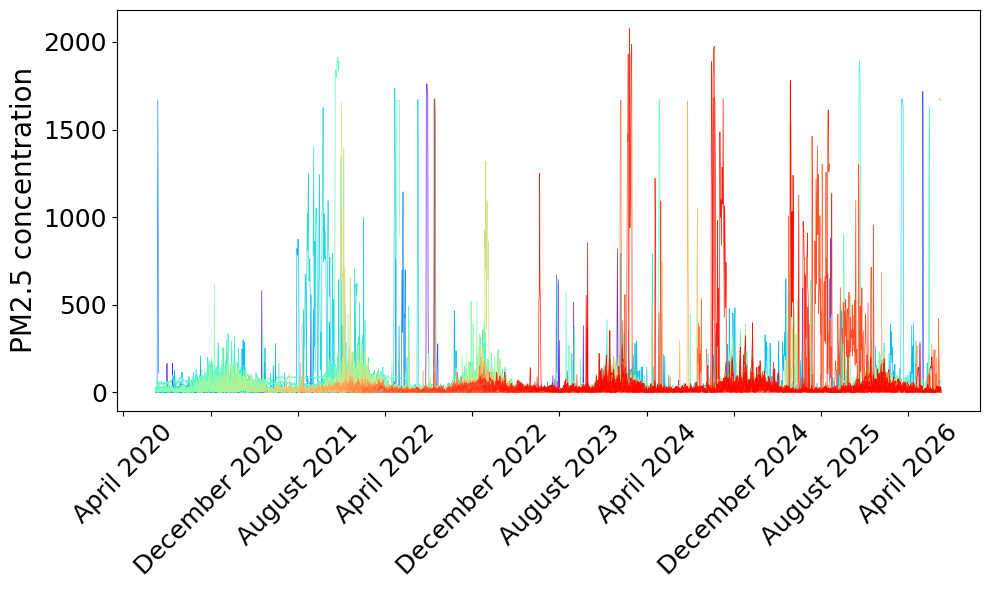

In [50]:
T, N = pollution.shape
cmap = plt.get_cmap('rainbow', N)

plt.figure(figsize=(10, 6))
for i in range(N):
    plt.plot(
        dates,
        pollution[:, i],
        color=cmap(i),
        # alpha=0.8,
        linewidth=0.5
    )

plt.ylabel('PM2.5 concentration', fontsize=20)

ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%B %Y'))  # "April 2026"
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=8))  # adjust spacing

plt.xticks(fontsize=18, rotation=45)  # rotation helps readability
plt.yticks(fontsize=18)

plt.tight_layout()
plt.show()

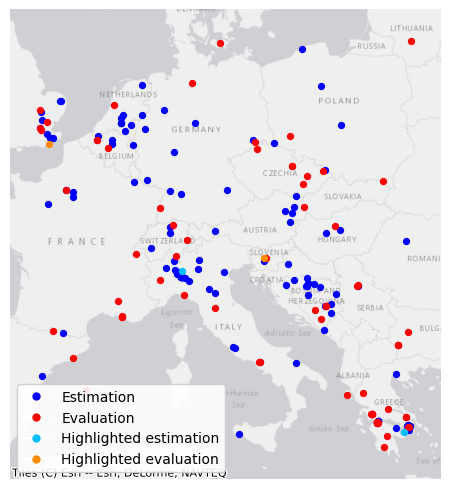

In [51]:
def plot_selected_points(selected_idx, longitude, latitude):
    group = np.array(['other'] * len(longitude), dtype=object)

    # evaluation points
    group[selected_idx] = 'selected'

    # special points
    group[[21, 62]] = 'special_estimation'
    group[[164, 181]] = 'special_evaluation'

    gdf = gpd.GeoDataFrame(
        {'group': group},
        geometry=gpd.points_from_xy(longitude, latitude),
        crs="EPSG:4326"
    ).to_crs(epsg=3857)

    fig, ax = plt.subplots(figsize=(6, 5))

    colors = {
        'other': 'blue',
        'selected': 'red',
        'special_estimation': 'deepskyblue',
        'special_evaluation': 'darkorange'
    }

    labels = {
        'other': 'Estimation',
        'selected': 'Evaluation',
        'special_estimation': 'Highlighted estimation',
        'special_evaluation': 'Highlighted evaluation'
    }

    # plot each group
    for group_name in colors:
        gdf[gdf['group'] == group_name].plot(
            ax=ax,
            color=colors[group_name],
            markersize=18
        )

    # legend
    legend_elements = [
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=colors[g], markersize=7,
               label=labels[g])
        for g in colors
    ]

    ax.legend(
        handles=legend_elements,
        loc='lower left',
        frameon=True,
        facecolor='white',
        framealpha=0.9
    )

    # rest unchanged...
    # --- ADD BOUNDARY PADDING ---
    xmin, ymin, xmax, ymax = gdf.total_bounds
    x_pad = (xmax - xmin) * 0.08
    y_pad = (ymax - ymin) * 0.08

    ax.set_xlim(xmin - x_pad, xmax + x_pad)
    ax.set_ylim(ymin - y_pad, ymax + y_pad)

    ctx.add_basemap(
        ax,
        source=ctx.providers.Esri.WorldGrayCanvas,
        zoom=5
    )

    ax.set_axis_off()

    plt.tight_layout()
    plt.show()

selected_idx = range(125, 200)
plot_selected_points(selected_idx, longitude=longitude, latitude=latitude)